In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io


In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")



Saving dataset_socialmedia_engagement_univ_vienna.csv to dataset_socialmedia_engagement_univ_vienna.csv
Dataset loaded successfully!


In [3]:
df.head(5)

,post_id,platform,post_type,post_time,likes,comments,shares,post_day,sentiment_score
0,1,Facebook,image,8/17/2023 14:45,2121,474,628,Thursday,positive
1,2,Facebook,carousel,5/14/2023 0:45,3660,432,694,Sunday,neutral
2,3,Instagram,poll,2/21/2023 16:15,4955,408,688,Tuesday,negative
3,4,Twitter,image,11/16/2023 0:45,1183,90,187,Thursday,negative
4,5,Twitter,video,5/23/2023 0:30,3499,247,286,Tuesday,positive


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()



Rows: 100
Columns: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   post_id          100 non-null    int64 
 1   platform         100 non-null    object
 2   post_type        100 non-null    object
 3   post_time        100 non-null    object
 4   likes            100 non-null    int64 
 5   comments         100 non-null    int64 
 6   shares           100 non-null    int64 
 7   post_day         100 non-null    object
 8   sentiment_score  100 non-null    object
dtypes: int64(4), object(5)
memory usage: 7.2+ KB


In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 post_id            0
platform           0
post_type          0
post_time          0
likes              0
comments           0
shares             0
post_day           0
sentiment_score    0
dtype: int64

Duplicate rows: 0


In [6]:
#Extracting only Instagram and Facebook data from the entire dataset

df_filtered = df[df['platform'].isin(['Instagram', 'Facebook'])]


In [7]:
df_filtered.describe().round(1)

,post_id,likes,comments,shares
count,68.0,68.0,68.0,68.0
mean,54.7,2841.1,240.2,501.3
std,29.0,1632.1,150.4,290.7
min,1.0,15.0,10.0,16.0
25%,30.8,1655.2,103.2,239.8
50%,59.0,3015.5,221.5,458.0
75%,79.2,4603.8,362.0,740.2
max,100.0,4992.0,500.0,993.0


In [8]:
df_filtered['platform'].value_counts().to_frame('Number of Posts')

,Number of Posts
platform,
Instagram,36
Facebook,32


In [9]:
df_filtered.groupby('post_type')[['likes', 'comments', 'shares']].mean().round(1)

,likes,comments,shares
post_type,,,
carousel,2352.7,276.9,602.9
image,2630.6,234.0,461.4
poll,3734.8,241.6,568.0
text,2197.8,158.6,336.8
video,3585.9,266.4,504.0


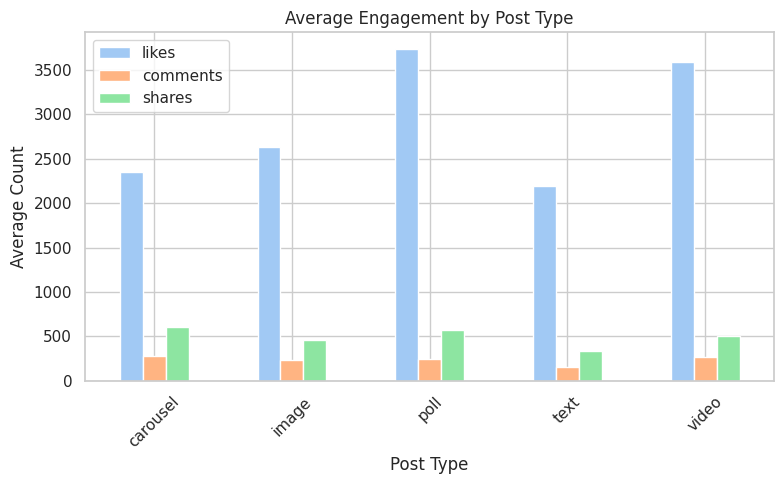

In [10]:
sns.set_theme(style="whitegrid", palette="pastel")
df_filtered.groupby('post_type')[['likes', 'comments', 'shares']].mean().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Engagement by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Average Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
df_filtered.groupby('platform')[['likes', 'comments', 'shares']].mean().round(1)


,likes,comments,shares
platform,,,
Facebook,2669.3,248.9,474.4
Instagram,2993.9,232.4,525.2


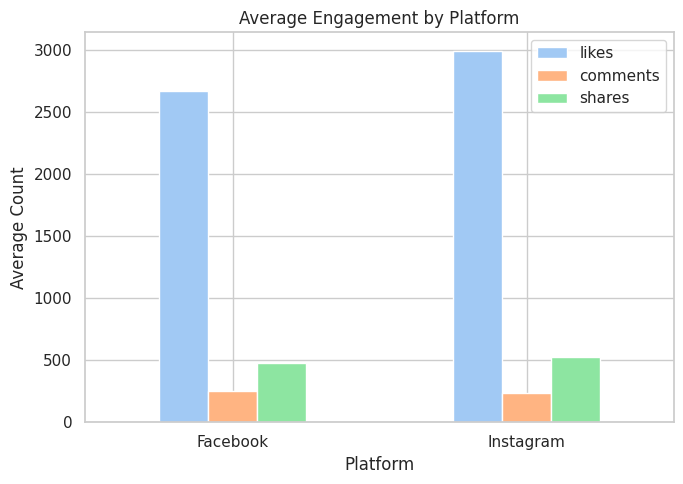

In [12]:
df_filtered.groupby('platform')[['likes', 'comments', 'shares']].mean().plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Average Engagement by Platform')
plt.xlabel('Platform')
plt.ylabel('Average Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
df_filtered.groupby('post_day')[['likes', 'comments', 'shares']].mean().round(1)

,likes,comments,shares
post_day,,,
Friday,3252.3,306.9,580.3
Monday,2495.2,211.6,475.4
Saturday,2585.5,223.0,395.5
Sunday,3180.2,286.6,629.9
Thursday,2664.4,192.2,376.2
Tuesday,2505.0,195.1,515.7
Wednesday,2936.5,251.0,493.6


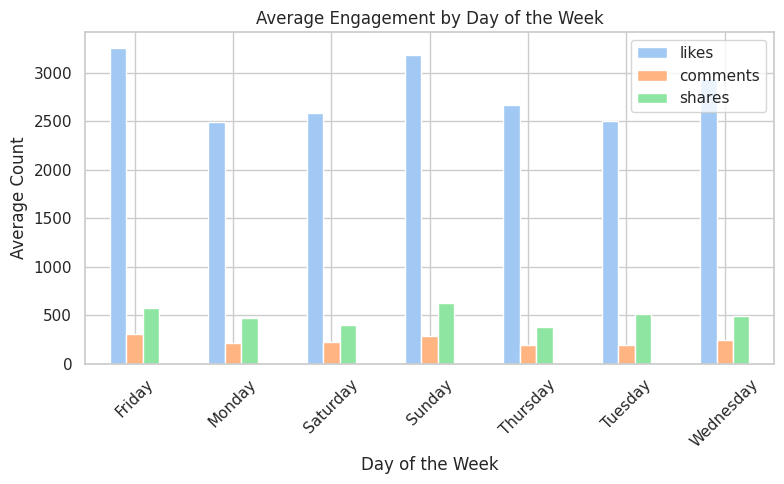

In [14]:
df_filtered.groupby('post_day')[['likes', 'comments', 'shares']].mean().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Engagement by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
df_filtered['post_time'].head()

,post_time
0,8/17/2023 14:45
1,5/14/2023 0:45
2,2/21/2023 16:15
5,5/5/2023 20:00
6,2/26/2023 11:45


In [16]:
df_filtered['post_hour'] = pd.to_datetime(
    df_filtered['post_time'], format='mixed'
).dt.hour

/tmp/ipykernel_4041/3386069158.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['post_hour'] = pd.to_datetime(


In [17]:
df_filtered[['post_time', 'post_hour']].head()

,post_time,post_hour
0,8/17/2023 14:45,14
1,5/14/2023 0:45,0
2,2/21/2023 16:15,16
5,5/5/2023 20:00,20
6,2/26/2023 11:45,11


In [18]:
df_filtered.groupby('post_hour')[['likes', 'comments', 'shares']].mean().round(1)

,likes,comments,shares
post_hour,,,
0,3193.6,286.9,495.6
1,4297.0,360.0,825.0
2,4929.0,252.0,730.0
3,3604.0,135.5,167.0
4,3569.8,187.7,632.3
5,2872.0,10.0,736.0
6,2731.0,265.8,510.5
7,2778.0,199.0,334.5
8,2456.0,313.3,243.3


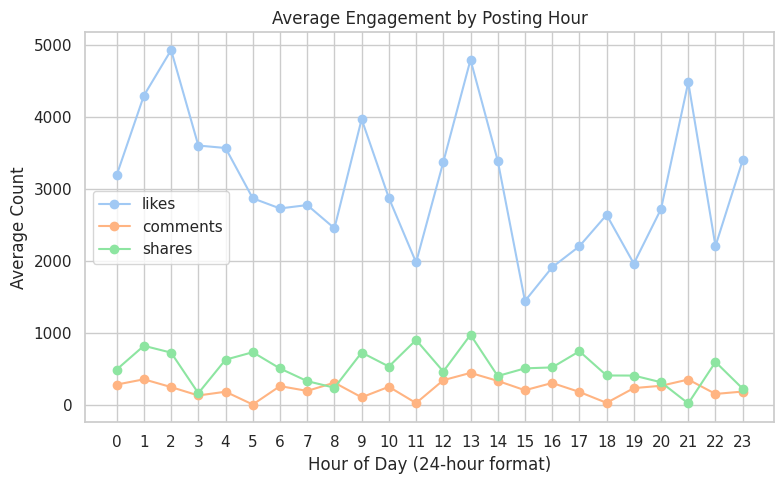

In [19]:
df_filtered.groupby('post_hour')[['likes', 'comments', 'shares']].mean().plot(
    kind='line',
    marker='o',
    figsize=(8, 5)
)

plt.title('Average Engagement by Posting Hour')
plt.xlabel('Hour of Day (24-hour format)')
plt.ylabel('Average Count')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

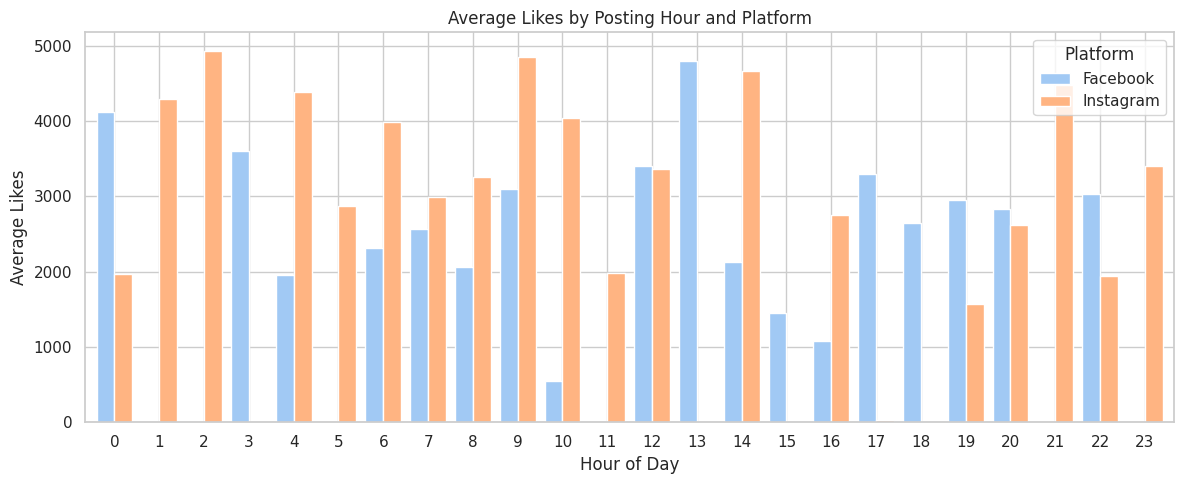

In [20]:
df_filtered.groupby(['post_hour', 'platform'])['likes'].mean().unstack().plot(
    kind='bar',
    figsize=(12, 5),
    width=0.8
)

plt.title('Average Likes by Posting Hour and Platform')
plt.xlabel('Hour of Day')
plt.ylabel('Average Likes')
plt.xticks(rotation=0)
plt.legend(title='Platform')
plt.tight_layout()
plt.show()

Posts by Type:
post_type
carousel    19
video       16
text        13
image       11
poll         9
Name: count, dtype: int64

Posts by Platform:
platform
Instagram    36
Facebook     32
Name: count, dtype: int64


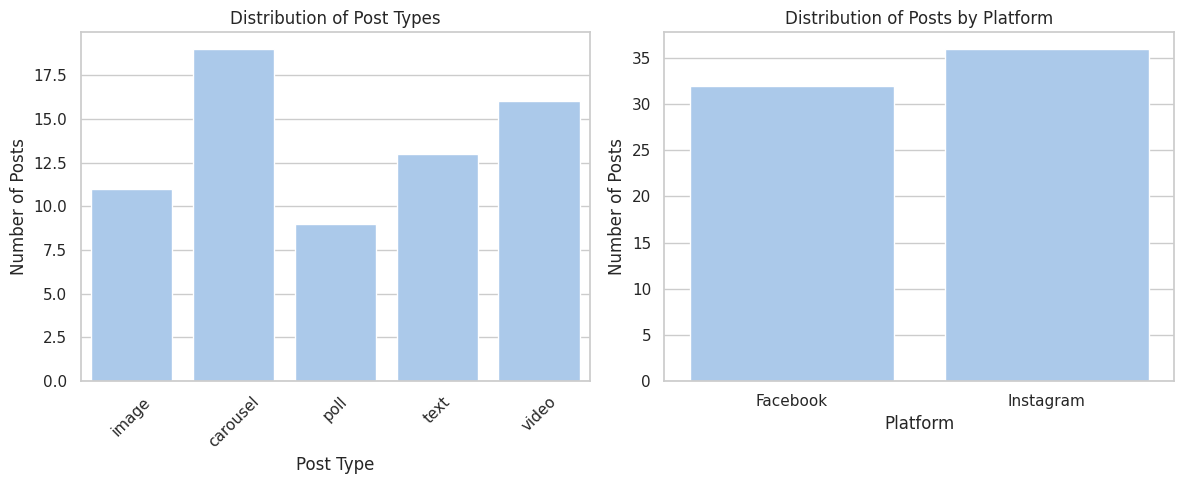

In [21]:
# Count posts by post type and platform
print("Posts by Type:")
print(df_filtered['post_type'].value_counts())

print("\nPosts by Platform:")
print(df_filtered['platform'].value_counts())

# Visualize distributions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df_filtered, x='post_type', ax=axes[0])
axes[0].set_title('Distribution of Post Types')
axes[0].set_xlabel('Post Type')
axes[0].set_ylabel('Number of Posts')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_filtered, x='platform', ax=axes[1])
axes[1].set_title('Distribution of Posts by Platform')
axes[1].set_xlabel('Platform')
axes[1].set_ylabel('Number of Posts')

plt.tight_layout()
plt.show()

Engagement Summary Statistics:


,likes,comments,shares
count,68.00,68.00,68.00
mean,2841.13,240.19,501.26
std,1632.13,150.38,290.68
min,15.00,10.00,16.00
25%,1655.25,103.25,239.75
50%,3015.50,221.50,458.00
75%,4603.75,362.00,740.25
max,4992.00,500.00,993.00


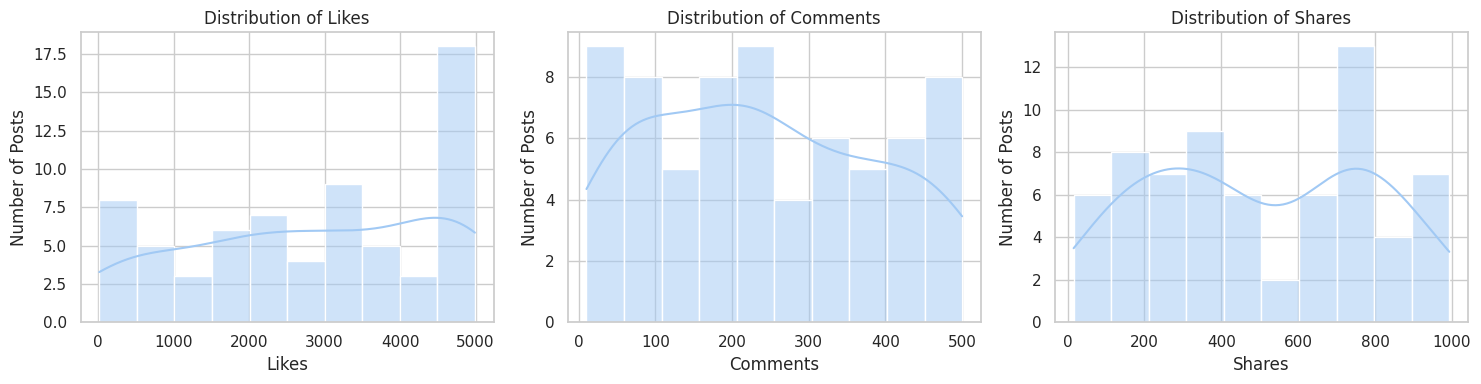

In [22]:
# Summary statistics for engagement
engagement_columns = ['likes', 'comments', 'shares']

print("Engagement Summary Statistics:")
display(df_filtered[engagement_columns].describe().round(2))

# Visualize the distribution of each engagement measure
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(engagement_columns):
    sns.histplot(data=df_filtered, x=column, bins=10, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {column.title()}')
    axes[i].set_xlabel(column.title())
    axes[i].set_ylabel('Number of Posts')

plt.tight_layout()
plt.show()

likes  comments  shares
platform  post_type                           
Facebook  carousel   2379.70    264.90  513.40
          image      1204.50    230.00  432.00
          poll       3868.00    331.00  786.33
          text       2484.67    178.00  454.50
          video      3365.56    259.44  359.11
Instagram carousel   2322.67    290.22  702.44
          image      3445.57    236.29  478.14
          poll       3668.17    196.83  458.83
          text       1952.00    142.00  236.00
          video      3869.14    275.29  690.29

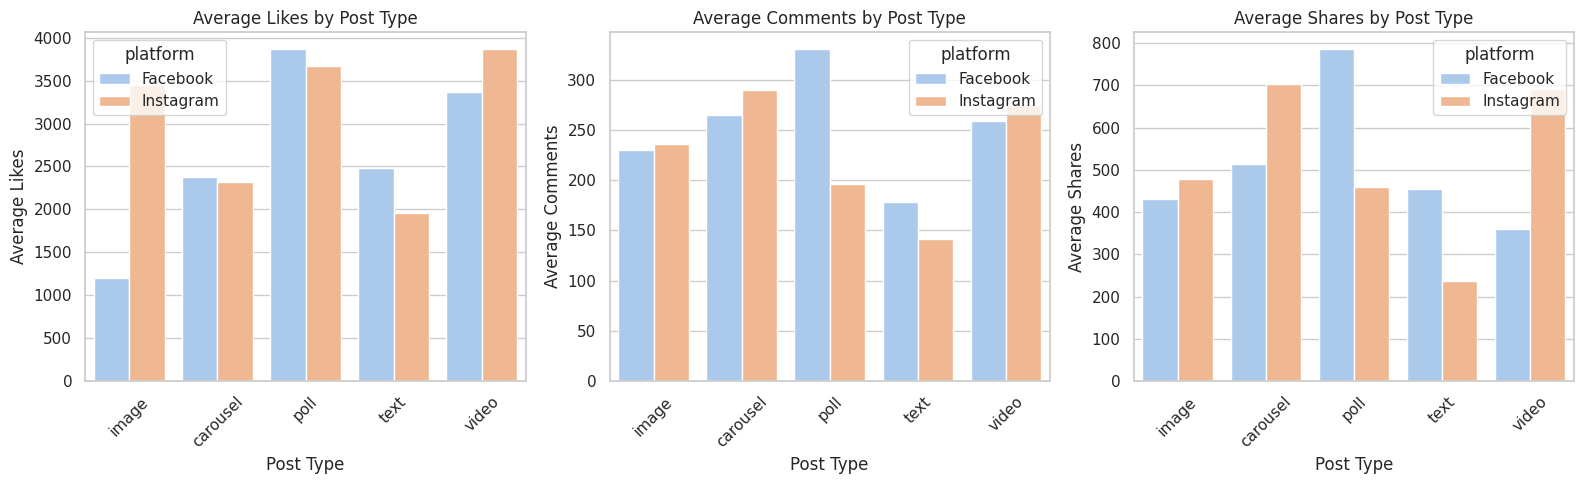

In [23]:
# Calculate average engagement by platform and post type
engagement_by_type = (
    df_filtered
    .groupby(['platform', 'post_type'])[['likes', 'comments', 'shares']]
    .mean()
    .round(2)
)

display(engagement_by_type)

# Visualize likes, comments, and shares
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, column in enumerate(['likes', 'comments', 'shares']):
    sns.barplot(
        data=df_filtered,
        x='post_type',
        y=column,
        hue='platform',
        ax=axes[i],
        errorbar=None
    )
    axes[i].set_title(f'Average {column.title()} by Post Type')
    axes[i].set_xlabel('Post Type')
    axes[i].set_ylabel(f'Average {column.title()}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [24]:
# Check sample sizes for our main variables
print("Posts by Platform:")
display(df_filtered['platform'].value_counts().to_frame('Number of Posts'))

print("Posts by Post Type:")
display(df_filtered['post_type'].value_counts().to_frame('Number of Posts'))

print("Posts by Day of Week:")
display(df_filtered['post_day'].value_counts().to_frame('Number of Posts'))

print("Posts by Posting Hour:")
display(df_filtered['post_hour'].value_counts().sort_index().to_frame('Number of Posts'))

# Check post type counts within each platform
print("Post Type Counts by Platform:")
display(pd.crosstab(df_filtered['post_type'], df_filtered['platform']))

Posts by Platform:


,Number of Posts
platform,
Instagram,36
Facebook,32


Posts by Post Type:


,Number of Posts
post_type,
carousel,19
video,16
text,13
image,11
poll,9


Posts by Day of Week:


,Number of Posts
post_day,
Wednesday,13
Thursday,12
Sunday,11
Tuesday,11
Friday,10
Saturday,6
Monday,5


Posts by Posting Hour:


,Number of Posts
post_hour,
0,7
1,1
2,1
3,2
4,6
5,1
6,4
7,2
8,3


Post Type Counts by Platform:


platform,Facebook,Instagram
post_type,,
carousel,10,9
image,4,7
poll,3,6
text,6,7
video,9,7


Average Engagement by Weekday and Platform:


likes  comments  shares
post_day  platform                            
Friday    Facebook   3495.50    275.50  676.50
          Instagram  3090.17    327.83  516.17
Monday    Facebook   1892.33    202.33  505.67
          Instagram  3399.50    225.50  430.00
Saturday  Facebook   1759.00    243.67  383.00
          Instagram  3412.00    202.33  408.00
Sunday    Facebook   3133.40    404.20  625.80
          Instagram  3219.17    188.67  633.33
Thursday  Facebook   2206.00    212.17  325.50
          Instagram  3122.83    172.17  426.83
Tuesday   Facebook   2307.40    121.20  542.00
          Instagram  2669.67    256.67  493.83
Wednesday Facebook   3340.17    270.83  336.00
          Instagram  2590.57    234.00  628.71

Average Engagement by Posting Hour and Platform:


likes  comments  shares
post_hour platform                            
0         Facebook   4113.75    277.25  494.50
          Instagram  1966.67    299.67  497.00
1         Instagram  4297.00    360.00  825.00
2         Instagram  4929.00    252.00  730.00
3         Facebook   3604.00    135.50  167.00
4         Facebook   1949.00    161.50  509.00
          Instagram  4380.25    200.75  694.00
5         Instagram  2872.00     10.00  736.00
6         Facebook   2314.00    249.67  572.00
          Instagram  3982.00    314.00  326.00
7         Facebook   2566.00    368.00  304.00
          Instagram  2990.00     30.00  365.00
8         Facebook   2054.50    445.00  276.50
          Instagram  3259.00     50.00  177.00
9         Facebook   3094.00     86.00  965.00
          Instagram  4846.00    134.00  498.00
10        Facebook    548.00    153.00  731.00
          Instagram  4041.50    308.00  440.50
11        Instagram  1982.00     30.00  906.00
12        Facebook   3404.00    244.00   67.00
          Instagram  3365.00    382.33  602.00
13        Facebook   4795.00    449.00  978.00
14        Facebook   2121.00    474.00  628.00
          Instagram  4665.00    202.00  183.00
15        Facebook   1446.67    208.33  512.00
16        Facebook   1072.50    171.50  367.50
          Instagram  2757.50    447.00  682.50
17        Facebook   3291.50    130.00  668.50
          Instagram    36.00    294.00  911.00
18        Facebook   2642.00     33.00  413.00
19        Facebook   2943.50    381.50  230.00
          Instagram  1574.20    180.60  484.60
20        Facebook   2827.00    407.00  333.00
          Instagram  2621.50    133.00  305.00
21        Instagram  4483.00    357.00   25.00
22        Facebook   3026.00     11.00  761.00
          Instagram  1936.67    205.67  547.33
23        Instagram  3401.00    190.00  230.00

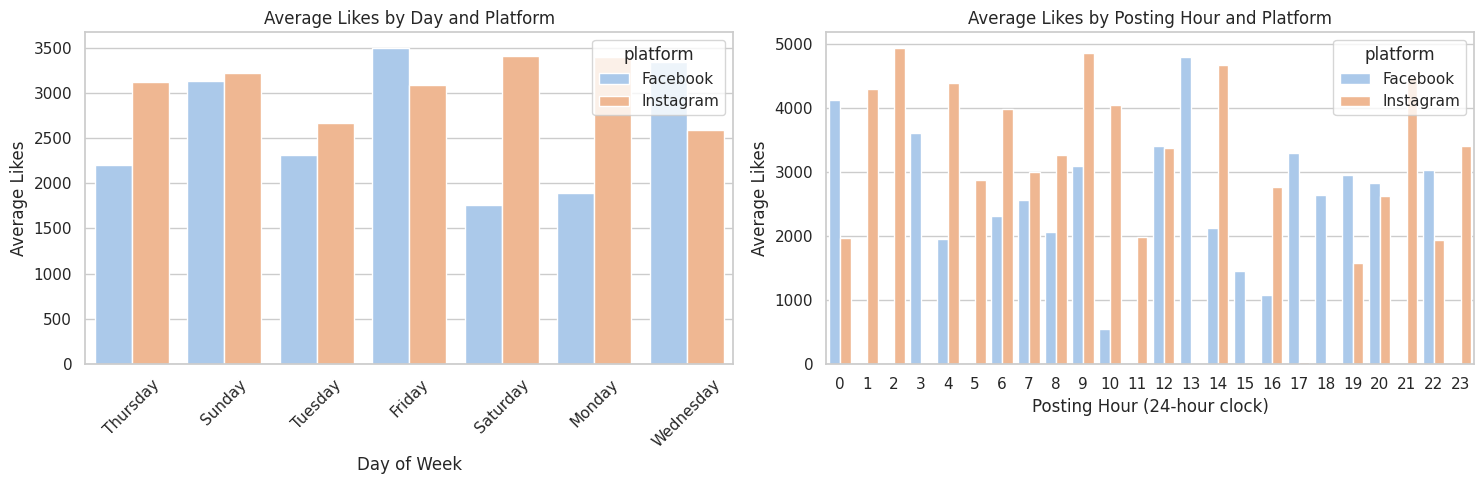

In [25]:
# Average engagement by weekday and platform
weekday_results = (
    df_filtered
    .groupby(['post_day', 'platform'])[['likes', 'comments', 'shares']]
    .mean()
    .round(2)
)

print("Average Engagement by Weekday and Platform:")
display(weekday_results)

# Average engagement by posting hour and platform
hour_results = (
    df_filtered
    .groupby(['post_hour', 'platform'])[['likes', 'comments', 'shares']]
    .mean()
    .round(2)
)

print("Average Engagement by Posting Hour and Platform:")
display(hour_results)

# Visualize average likes by weekday and posting hour
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=df_filtered,
    x='post_day',
    y='likes',
    hue='platform',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Average Likes by Day and Platform')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Average Likes')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=df_filtered,
    x='post_hour',
    y='likes',
    hue='platform',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Average Likes by Posting Hour and Platform')
axes[1].set_xlabel('Posting Hour (24-hour clock)')
axes[1].set_ylabel('Average Likes')

plt.tight_layout()
plt.show()

In [26]:
# Overall engagement averages by platform
print("1. Average Engagement by Platform")
display(
    df_filtered.groupby('platform')[['likes', 'comments', 'shares']]
    .mean().round(2)
)

# Overall engagement averages by post type
print("\n2. Average Engagement by Post Type")
display(
    df_filtered.groupby('post_type')[['likes', 'comments', 'shares']]
    .mean().round(2)
)

# Highest-average categories for each engagement measure
print("\n3. Highest Average Engagement Categories")

for metric in ['likes', 'comments', 'shares']:
    best_type = df_filtered.groupby('post_type')[metric].mean().idxmax()
    best_platform = df_filtered.groupby('platform')[metric].mean().idxmax()

    print(f"\n{metric.title()}:")
    print(f"  Highest-average post type: {best_type}")
    print(f"  Highest-average platform: {best_platform}")

# Missing values and duplicate rows
print("\n4. Data Quality")
print("Missing values:")
display(df_filtered.isnull().sum().to_frame('Missing Values'))
print("Duplicate rows:", df_filtered.duplicated().sum())
print("Total posts analyzed:", len(df_filtered))

1. Average Engagement by Platform


,likes,comments,shares
platform,,,
Facebook,2669.28,248.91,474.38
Instagram,2993.89,232.44,525.17



2. Average Engagement by Post Type


,likes,comments,shares
post_type,,,
carousel,2352.68,276.89,602.95
image,2630.64,234.00,461.36
poll,3734.78,241.56,568.00
text,2197.85,158.62,336.85
video,3585.88,266.38,504.00



3. Highest Average Engagement Categories

Likes:
  Highest-average post type: poll
  Highest-average platform: Instagram

Comments:
  Highest-average post type: carousel
  Highest-average platform: Facebook

Shares:
  Highest-average post type: carousel
  Highest-average platform: Instagram

4. Data Quality
Missing values:


,Missing Values
post_id,0
platform,0
post_type,0
post_time,0
likes,0
comments,0
shares,0
post_day,0
sentiment_score,0
post_hour,0


Duplicate rows: 0
Total posts analyzed: 68


Correlation Matrix:


,likes,comments,shares
likes,1.00,0.13,0.11
comments,0.13,1.00,0.09
shares,0.11,0.09,1.00


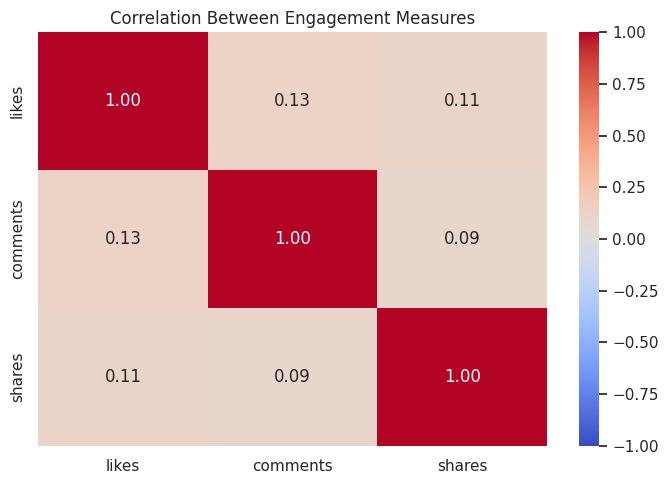

In [27]:

# Calculate correlations between engagement measures
engagement_columns = ['likes', 'comments', 'shares']
correlation_matrix = df_filtered[engagement_columns].corr().round(2)

print("Correlation Matrix:")
display(correlation_matrix)

# Visualize the correlations
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Engagement Measures')
plt.tight_layout()
plt.show()


/tmp/ipykernel_4041/3153874779.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['total_engagement'] = (


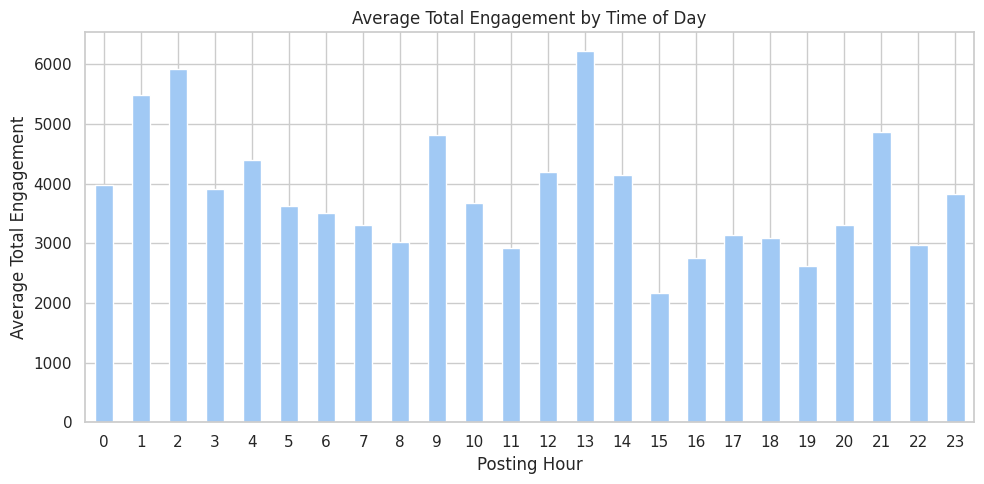

In [31]:
# Calculate total engagement for each post
df_filtered['total_engagement'] = (
    df_filtered['likes'] +
    df_filtered['comments'] +
    df_filtered['shares']
)

# Calculate average total engagement by posting hour
engagement_by_hour = df_filtered.groupby('post_hour')['total_engagement'].mean()

# Create bar chart
engagement_by_hour.plot(kind='bar', figsize=(10, 5))

plt.title('Average Total Engagement by Time of Day')
plt.xlabel('Posting Hour')
plt.ylabel('Average Total Engagement')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

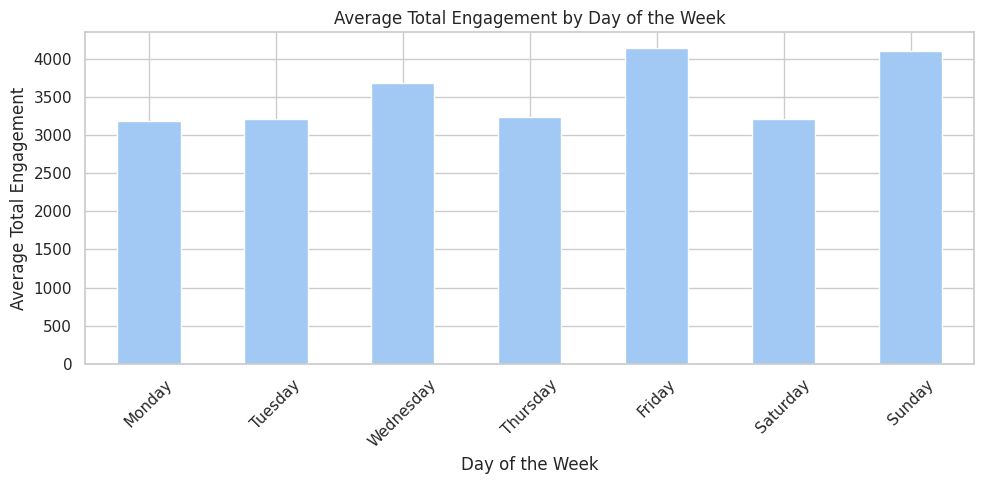

In [32]:
# Calculate average total engagement by day of the week
engagement_by_day = df_filtered.groupby('post_day')['total_engagement'].mean()

# Set days in calendar order
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

engagement_by_day = engagement_by_day.reindex(day_order)

# Create bar chart
engagement_by_day.plot(kind='bar', figsize=(10, 5))

plt.title('Average Total Engagement by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total Engagement')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()